# Automated Web Security Scanner

The scanner audits a website for missing security headers, insecure cookie flags, version disclosure and CORS misconfigurations. Each finding receives a severity, and each site receives a score and a grade.

The scanner must only be used on systems that the tester owns or has permission to test.

## 1. Importing Libraries

In [1]:
import html
import json
import re
import threading
import time
from dataclasses import dataclass, asdict
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from urllib.parse import urlparse

import matplotlib.pyplot as plt
import pandas as pd
import requests
import urllib3

urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

## 2. Defining the severity model and the header rules

In [2]:
TIMEOUT = 10
USER_AGENT = "WebSecScanner/1.0 (educational security audit)"
SEVERITY_ORDER = ["Critical", "High", "Medium", "Low", "Info"]
SEVERITY_WEIGHT = {"Critical": 25, "High": 15, "Medium": 8, "Low": 3, "Info": 0}
LOCAL_HOSTS = {"localhost", "127.0.0.1", "::1"}

# Each header maps to its severity when missing, its purpose and its recommended value.
SECURITY_HEADERS = {
    "Strict-Transport-Security": ("High", "Forces HTTPS and prevents SSL-stripping / downgrade attacks.",
                                  "max-age=31536000; includeSubDomains"),
    "Content-Security-Policy": ("High", "Main defence against XSS and data injection.",
                                "default-src 'self'; object-src 'none'; frame-ancestors 'none'"),
    "X-Frame-Options": ("Medium", "Prevents clickjacking by blocking framing.", "DENY or SAMEORIGIN"),
    "X-Content-Type-Options": ("Low", "Stops MIME-type sniffing.", "nosniff"),
    "Referrer-Policy": ("Low", "Limits URL leakage to third parties.", "strict-origin-when-cross-origin"),
    "Permissions-Policy": ("Low", "Restricts browser features such as camera and geolocation.",
                           "geolocation=(), camera=(), microphone=()"),
}

@dataclass
class Finding:
    url: str
    category: str
    check: str
    status: str
    severity: str
    detail: str
    recommendation: str = ""

## 3. The HTTP helpers fetch pages and collect cookies

In [3]:
def normalise_url(url: str) -> str:
    url = url.strip()
    if not re.match(r"^https?://", url, re.I):
        url = "https://" + url
    return url

def fetch(url, headers=None, method="GET", verify=True):
    h = {"User-Agent": USER_AGENT}
    if headers:
        h.update(headers)
    return requests.request(method, url, headers=h, timeout=TIMEOUT,
                            allow_redirects=True, verify=verify)

def raw_set_cookies(resp):
    # Cookies set during redirects are included.
    cookies = []
    for r in list(resp.history) + [resp]:
        try:
            cookies += r.raw.headers.getlist("Set-Cookie")
        except AttributeError:
            v = r.headers.get("Set-Cookie")
            if v:
                cookies.append(v)
    return cookies

## 4. The check modules inspect each response

### 4.1 The transport, header and disclosure checks examine the response headers

In [4]:
def check_transport(url, resp):
    p = urlparse(url)
    out = []
    if p.scheme == "http" and p.hostname not in LOCAL_HOSTS:
        out.append(Finding(url, "Transport", "HTTPS enforced", "FAIL", "Medium",
                           "Site is reachable over plain HTTP.", "Serve the site over HTTPS and redirect HTTP to HTTPS."))
    elif resp.url.startswith("https://") and p.scheme == "http":
        out.append(Finding(url, "Transport", "HTTPS enforced", "PASS", "Info", "HTTP redirects to HTTPS."))
    elif p.scheme == "https":
        out.append(Finding(url, "Transport", "HTTPS enforced", "PASS", "Info", "Site uses HTTPS."))
    return out


def check_headers(url, resp):
    out, h = [], resp.headers
    final_https = resp.url.startswith("https://")
    csp = h.get("Content-Security-Policy", "")

    for name, (sev, why, fix) in SECURITY_HEADERS.items():
        val = h.get(name)

        if name == "Strict-Transport-Security" and not final_https:
            out.append(Finding(url, "Header", name, "INFO", "Info", "Not applicable: response was not served over HTTPS."))
            continue

        # A CSP frame-ancestors directive replaces X-Frame-Options.
        if name == "X-Frame-Options" and not val and "frame-ancestors" in csp.lower():
            out.append(Finding(url, "Header", name, "PASS", "Info", "Covered by CSP frame-ancestors."))
            continue

        if not val:
            out.append(Finding(url, "Header", name, "FAIL", sev, f"Header missing. {why}", f"Add: {name}: {fix}"))
            continue

        weak = None
        if name == "Strict-Transport-Security":
            m = re.search(r"max-age=(\d+)", val, re.I)
            if not m or int(m.group(1)) < 15552000:
                weak = "max-age is below 180 days (15552000 seconds)."
        elif name == "Content-Security-Policy":
            bad = [t for t in ("'unsafe-inline'", "'unsafe-eval'") if t in val]
            if bad or re.search(r"(script-src|default-src)[^;]*\s\*(\s|;|$)", val):
                weak = "Policy is permissive (" + ", ".join(bad or ["wildcard source"]) + ")."
        elif name == "X-Frame-Options":
            if val.strip().upper() not in ("DENY", "SAMEORIGIN"):
                weak = f"Unexpected value '{val}'."
        elif name == "X-Content-Type-Options":
            if val.strip().lower() != "nosniff":
                weak = f"Value should be 'nosniff', got '{val}'."
        elif name == "Referrer-Policy":
            if val.strip().lower() in ("unsafe-url", "no-referrer-when-downgrade"):
                weak = f"Value '{val}' leaks full URLs."

        if weak:
            out.append(Finding(url, "Header", name, "FAIL", "Medium" if sev in ("High", "Medium") else "Low",
                               f"Weak configuration: {weak}", f"Use: {name}: {fix}"))
        else:
            out.append(Finding(url, "Header", name, "PASS", "Info", f"Present: {val[:80]}"))
    return out


def check_disclosure(url, resp):
    out = []
    for name in ("Server", "X-Powered-By", "X-AspNet-Version", "X-Generator"):
        val = resp.headers.get(name)
        if val and re.search(r"\d", val):
            out.append(Finding(url, "Disclosure", name, "FAIL", "Low",
                               f"Reveals software/version: '{val}'.", f"Remove or genericise the {name} header."))
        elif val:
            out.append(Finding(url, "Disclosure", name, "INFO", "Info", f"Present without version: '{val}'."))
    return out

### 4.2 The cookie check examines the flags on every cookie

In [5]:
def check_cookies(url, resp):
    out = []
    https = resp.url.startswith("https://")
    for raw in raw_set_cookies(resp):
        parts = [p.strip() for p in raw.split(";")]
        name = parts[0].split("=", 1)[0]
        flags = {p.split("=", 1)[0].lower(): (p.split("=", 1)[1] if "=" in p else True) for p in parts[1:]}
        problems = []
        if "secure" not in flags:
            problems.append(("Secure flag missing", "Medium" if https else "Low"))
        if "httponly" not in flags:
            problems.append(("HttpOnly flag missing (readable by JavaScript)", "Medium"))
        samesite = str(flags.get("samesite", "")).lower()
        if not samesite:
            problems.append(("SameSite attribute missing", "Low"))
        elif samesite == "none" and "secure" not in flags:
            problems.append(("SameSite=None without Secure", "Medium"))
        if problems:
            # The most severe problem sets the severity of the cookie.
            sev = min((s for _, s in problems), key=SEVERITY_ORDER.index)
            out.append(Finding(url, "Cookie", f"Cookie '{name}'", "FAIL", sev,
                               "; ".join(p for p, _ in problems) + ".",
                               "Set cookies with Secure; HttpOnly; SameSite=Lax (or Strict)."))
        else:
            out.append(Finding(url, "Cookie", f"Cookie '{name}'", "PASS", "Info", "Secure, HttpOnly and SameSite all set."))
    if not out:
        out.append(Finding(url, "Cookie", "Cookies", "INFO", "Info", "No cookies set on this response."))
    return out

### 4.3 The CORS checks probe the server with crafted origins

In [6]:
ATTACKER = "evil-attacker.com"

def cors_probe_origins(host):
    return {
        "Arbitrary origin": f"https://{ATTACKER}",
        "Null origin": "null",
        "Lookalike suffix": f"https://{host}.{ATTACKER}",
        "Lookalike prefix": f"https://evil-{host}",
    }

def check_cors(url):
    out, host = [], urlparse(url).hostname
    for label, origin in cors_probe_origins(host).items():
        try:
            r = fetch(url, headers={"Origin": origin})
        except requests.RequestException as e:
            out.append(Finding(url, "CORS", label, "ERROR", "Info", f"Request failed: {e}"))
            continue
        acao = r.headers.get("Access-Control-Allow-Origin")
        acac = r.headers.get("Access-Control-Allow-Credentials", "").lower() == "true"
        vary = "origin" in r.headers.get("Vary", "").lower()

        if acao is None:
            out.append(Finding(url, "CORS", label, "PASS", "Info", "Origin not allowed (no ACAO header)."))
            continue
        if acao == "*":
            if acac:
                out.append(Finding(url, "CORS", label, "FAIL", "High",
                                   "ACAO '*' combined with ACAC 'true' (insecure and invalid combination).",
                                   "Never combine wildcard with credentials; use an explicit allow-list."))
            else:
                out.append(Finding(url, "CORS", label, "FAIL", "Low",
                                   "Wildcard ACAO '*': any site can read responses (fine only for fully public data).",
                                   "Restrict to an allow-list if the endpoint returns anything non-public."))
        elif acao == origin:
            if origin == "null":
                sev = "High" if acac else "Medium"
            else:
                sev = "Critical" if acac else "Medium"
            note = "" if vary else " Vary: Origin missing (cache-poisoning risk)."
            out.append(Finding(url, "CORS", label, "FAIL", sev,
                               f"Origin '{origin}' reflected in ACAO" + (" with credentials allowed." if acac else ".") + note,
                               "Validate Origin against an exact-match allow-list; never reflect it blindly."))
        else:
            out.append(Finding(url, "CORS", label, "PASS", "Info", f"ACAO is a fixed value ('{acao}'), not reflected."))

    try:
        pf = fetch(url, method="OPTIONS", headers={
            "Origin": f"https://{ATTACKER}",
            "Access-Control-Request-Method": "DELETE",
        })
        methods = pf.headers.get("Access-Control-Allow-Methods", "")
        pf_acao = pf.headers.get("Access-Control-Allow-Origin")
        risky = [m for m in ("PUT", "DELETE", "PATCH") if m in methods.upper()]
        if pf_acao in (f"https://{ATTACKER}", "*") and risky:
            out.append(Finding(url, "CORS", "Preflight", "FAIL", "Medium",
                               f"Untrusted origin may use state-changing methods: {', '.join(risky)}.",
                               "Limit Access-Control-Allow-Methods and origins for preflight."))
        else:
            out.append(Finding(url, "CORS", "Preflight", "PASS", "Info", "No risky methods allowed to untrusted origins."))
    except requests.RequestException as e:
        out.append(Finding(url, "CORS", "Preflight", "ERROR", "Info", f"Request failed: {e}"))
    return out

## 5. The scan engine collects findings and computes scores and grades

In [7]:
def score_and_grade(findings):
    penalty = sum(SEVERITY_WEIGHT[f.severity] for f in findings if f.status == "FAIL")
    score = max(0, 100 - penalty)
    grade = "A" if score >= 90 else "B" if score >= 80 else "C" if score >= 65 else "D" if score >= 50 else "F"
    return score, grade


def scan_url(url, verify=True):
    url = normalise_url(url)
    try:
        resp = fetch(url, verify=verify)
    except requests.RequestException as e:
        return [Finding(url, "Connection", "Reachability", "ERROR", "Info", f"Could not connect: {e}")]
    findings = []
    findings += check_transport(url, resp)
    findings += check_headers(url, resp)
    findings += check_disclosure(url, resp)
    findings += check_cookies(url, resp)
    findings += check_cors(url)
    return findings


def scan_many(urls, verify=True, delay=0.5):
    all_findings = []
    for u in urls:
        print(f"[*] Scanning {u}")
        all_findings += scan_url(u, verify=verify)
        time.sleep(delay)
    return all_findings


def to_dataframe(findings):
    return pd.DataFrame([asdict(f) for f in findings])


def summarise(df):
    rows = []
    for url, g in df.groupby("url", sort=False):
        if (g.category == "Connection").any():
            rows.append({"url": url, "score": "N/A", "grade": "ERROR",
                         **{s: 0 for s in SEVERITY_ORDER[:4]}})
            continue
        fl = [Finding(**r) for r in g.to_dict("records")]
        score, grade = score_and_grade(fl)
        counts = g[g.status == "FAIL"].severity.value_counts()
        rows.append({"url": url, "score": score, "grade": grade,
                     **{s: int(counts.get(s, 0)) for s in SEVERITY_ORDER[:4]}})
    return pd.DataFrame(rows)

## 6. The report generator produces a chart and HTML, CSV and JSON files

In [8]:
SEV_COLOUR = {"Critical": "#7f1d1d", "High": "#dc2626", "Medium": "#ea580c", "Low": "#ca8a04", "Info": "#6b7280"}

def make_chart(summary_df, path="severity_chart.png"):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    bottom = [0] * len(summary_df)
    labels = [u.replace("http://", "").replace("https://", "") for u in summary_df.url]
    for sev in SEVERITY_ORDER[:4]:
        ax.bar(labels, summary_df[sev], bottom=bottom, label=sev, color=SEV_COLOUR[sev])
        bottom = [b + v for b, v in zip(bottom, summary_df[sev])]
    ax.set_ylabel("Number of failed checks")
    ax.set_title("Findings by severity per target")
    ax.legend()
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    fig.savefig(path, dpi=150)
    return fig


def build_html_report(df, summary_df, path="scan_report.html"):
    e = html.escape
    parts = ["<!DOCTYPE html><html><head><meta charset='utf-8'><title>Web Security Scan Report</title>",
             "<style>body{font-family:Segoe UI,Arial,sans-serif;margin:2rem;color:#111}",
             "table{border-collapse:collapse;width:100%;margin-bottom:2rem}th,td{border:1px solid #ddd;padding:6px 8px;font-size:14px;vertical-align:top}",
             "th{background:#1f2937;color:#fff;text-align:left}.badge{color:#fff;padding:2px 8px;border-radius:10px;font-size:12px}",
             ".PASS{color:#15803d;font-weight:bold}.FAIL{color:#b91c1c;font-weight:bold}</style></head><body>",
             "<h1>Web Security Scan Report</h1>",
             f"<p>Generated: {time.strftime('%Y-%m-%d %H:%M:%S')}</p><h2>Summary</h2>",
             "<table><tr><th>Target</th><th>Score</th><th>Grade</th><th>Critical</th><th>High</th><th>Medium</th><th>Low</th></tr>"]
    for r in summary_df.itertuples():
        score_txt = f"{r.score}/100" if isinstance(r.score, (int, float)) else str(r.score)
        parts.append(f"<tr><td>{e(r.url)}</td><td>{score_txt}</td><td><b>{r.grade}</b></td>"
                     f"<td>{r.Critical}</td><td>{r.High}</td><td>{r.Medium}</td><td>{r.Low}</td></tr>")
    parts.append("</table>")
    for url, g in df.groupby("url", sort=False):
        parts.append(f"<h2>{e(url)}</h2><table><tr><th>Category</th><th>Check</th><th>Status</th><th>Severity</th><th>Detail</th><th>Recommendation</th></tr>")
        g = g.assign(_o=g.apply(lambda r: (0 if r.status == "FAIL" else 1, SEVERITY_ORDER.index(r.severity)), axis=1)).sort_values("_o")
        for r in g.itertuples():
            badge = f"<span class='badge' style='background:{SEV_COLOUR[r.severity]}'>{e(r.severity)}</span>" if r.status == "FAIL" else ""
            parts.append(f"<tr><td>{e(r.category)}</td><td>{e(r.check)}</td><td class='{e(r.status)}'>{e(r.status)}</td>"
                         f"<td>{badge}</td><td>{e(r.detail)}</td><td>{e(r.recommendation)}</td></tr>")
        parts.append("</table>")
    parts.append("</body></html>")
    with open(path, "w", encoding="utf-8") as fh:
        fh.write("".join(parts))
    return path

## 7. The local test lab hosts three servers with known configurations

- Port 8081 serves a vulnerable profile with no security headers, reflected origins, version leaks and an unprotected cookie.
- Port 8082 serves a hardened profile with all security headers, a strict CORS allow-list and a protected cookie.
- Port 8083 serves a mixed profile with partial headers, wildcard CORS and a partially protected cookie.

In [9]:
class LabHandler(BaseHTTPRequestHandler):
    def log_message(self, *a):
        pass

    def _send(self, headers, body=b"lab"):
        self.send_response_only(200)
        for k, v in headers:
            self.send_header(k, v)
        self.send_header("Content-Length", str(len(body)))
        self.end_headers()
        if self.command != "HEAD":
            self.wfile.write(body)

    def _headers_for(self):
        origin = self.headers.get("Origin")
        port = self.server.server_port
        # Vulnerable profile
        if port == 8081:
            h = [("Server", "Apache/2.2.8 (Ubuntu)"), ("X-Powered-By", "PHP/5.2.4"),
                 ("Set-Cookie", "PHPSESSID=abc123; Path=/")]
            if origin:
                h += [("Access-Control-Allow-Origin", origin), ("Access-Control-Allow-Credentials", "true"),
                      ("Access-Control-Allow-Methods", "GET, POST, PUT, DELETE")]
            return h
        # Hardened profile
        if port == 8082:
            h = [("Server", "nginx"), ("Strict-Transport-Security", "max-age=63072000; includeSubDomains"),
                 ("Content-Security-Policy", "default-src 'self'; object-src 'none'; frame-ancestors 'none'"),
                 ("X-Frame-Options", "DENY"), ("X-Content-Type-Options", "nosniff"),
                 ("Referrer-Policy", "strict-origin-when-cross-origin"),
                 ("Permissions-Policy", "geolocation=(), camera=()"),
                 ("Set-Cookie", "sid=xyz; Path=/; Secure; HttpOnly; SameSite=Strict"), ("Vary", "Origin")]
            if origin == "https://trusted.example.com":
                h.append(("Access-Control-Allow-Origin", origin))
            return h
        # Mixed profile
        h = [("Server", "gunicorn/20.1.0"), ("X-Content-Type-Options", "nosniff"),
             ("Content-Security-Policy", "default-src 'self' 'unsafe-inline'"),
             ("Set-Cookie", "session=q1; Path=/; HttpOnly"),
             ("Access-Control-Allow-Origin", "*")]
        return h

    def do_GET(self):     self._send(self._headers_for())
    def do_HEAD(self):    self._send(self._headers_for())
    def do_OPTIONS(self): self._send(self._headers_for())


def start_lab(ports=(8081, 8082, 8083)):
    servers = []
    for p in ports:
        srv = ThreadingHTTPServer(("127.0.0.1", p), LabHandler)
        threading.Thread(target=srv.serve_forever, daemon=True).start()
        servers.append(srv)
    return servers

In [10]:
#servers from an earlier run are stopped to free the ports.
try:
    for s in lab_servers:
        s.shutdown()
        s.server_close()
except NameError:
    pass

lab_servers = start_lab()
print("Lab servers running on ports 8081, 8082, 8083")

Lab servers running on ports 8081, 8082, 8083


## 8. The scanner audits the three local lab servers

In [11]:
LAB_TARGETS = ["http://127.0.0.1:8081", "http://127.0.0.1:8082", "http://127.0.0.1:8083"]
lab_findings = scan_many(LAB_TARGETS, delay=0.1)
lab_df = to_dataframe(lab_findings)
lab_summary = summarise(lab_df)
lab_summary

[*] Scanning http://127.0.0.1:8081
[*] Scanning http://127.0.0.1:8082
[*] Scanning http://127.0.0.1:8083


,url,score,grade,Critical,High,Medium,Low
0,http://127.0.0.1:8081,0,F,3,2,3,5
1,http://127.0.0.1:8082,100,A,0,0,0,0
2,http://127.0.0.1:8083,60,D,0,0,2,8


In [12]:
fails = lab_df[lab_df.status == "FAIL"].copy()
fails["rank"] = fails.severity.map(SEVERITY_ORDER.index)
fails.sort_values(["url", "rank"])[["url", "category", "check", "severity", "detail"]].reset_index(drop=True)

,url,category,check,severity,detail
0,http://127.0.0.1:8081,CORS,Arbitrary origin,Critical,Origin 'https://evil-attacker.com' reflected i...
1,http://127.0.0.1:8081,CORS,Lookalike suffix,Critical,Origin 'https://127.0.0.1.evil-attacker.com' r...
2,http://127.0.0.1:8081,CORS,Lookalike prefix,Critical,Origin 'https://evil-127.0.0.1' reflected in A...
3,http://127.0.0.1:8081,Header,Content-Security-Policy,High,Header missing. Main defence against XSS and d...
4,http://127.0.0.1:8081,CORS,Null origin,High,Origin 'null' reflected in ACAO with credentia...
5,http://127.0.0.1:8081,Header,X-Frame-Options,Medium,Header missing. Prevents clickjacking by block...
6,http://127.0.0.1:8081,Cookie,Cookie 'PHPSESSID',Medium,Secure flag missing; HttpOnly flag missing (re...
7,http://127.0.0.1:8081,CORS,Preflight,Medium,Untrusted origin may use state-changing method...
8,http://127.0.0.1:8081,Header,X-Content-Type-Options,Low,Header missing. Stops MIME-type sniffing.
9,http://127.0.0.1:8081,Header,Referrer-Policy,Low,Header missing. Limits URL leakage to third pa...


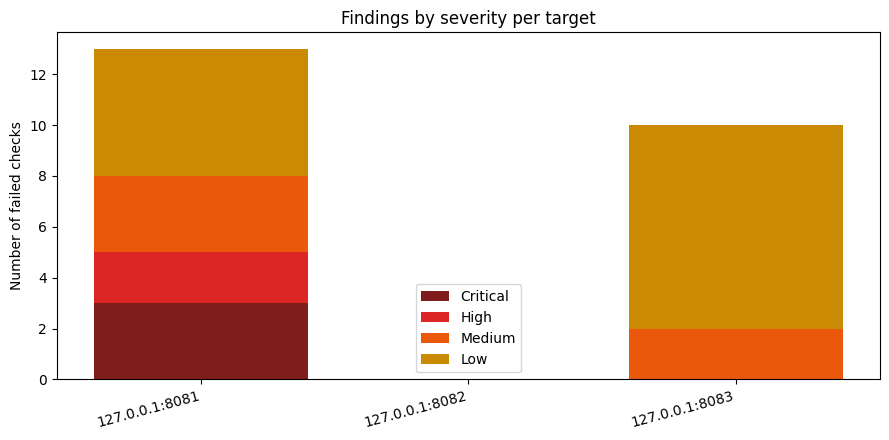

In [13]:
fig = make_chart(lab_summary)
plt.show()

## 9. The scanner audits live targets when `RUN_LIVE` is `True`

The targets are public practice sites intended for security testing.

In [14]:
RUN_LIVE = True
LIVE_TARGETS = [
    "http://testphp.vulnweb.com",
    "http://demo.testfire.net",
    "https://httpbin.org",
]

if RUN_LIVE:
    live_df = to_dataframe(scan_many(LIVE_TARGETS))
    live_summary = summarise(live_df)
    display(live_summary)
else:
    live_df, live_summary = None, None
    print("Live scan skipped (RUN_LIVE = False).")

[*] Scanning http://testphp.vulnweb.com
[*] Scanning http://demo.testfire.net
[*] Scanning https://httpbin.org


,url,score,grade,Critical,High,Medium,Low
0,http://testphp.vulnweb.com,N/A,ERROR,0,0,0,0
1,http://demo.testfire.net,54,D,0,1,2,5
2,https://httpbin.org,0,F,3,3,2,4


## 10. The scan results are exported as HTML, CSV and JSON

In [15]:
report_df = pd.concat([lab_df] + ([live_df] if live_df is not None else []), ignore_index=True)
report_summary = summarise(report_df)

html_path = build_html_report(report_df, report_summary, "scan_report.html")
report_df.to_csv("scan_results.csv", index=False)
with open("scan_results.json", "w") as fh:
    json.dump(report_df.to_dict("records"), fh, indent=2)
print("Saved:", html_path, "| scan_results.csv | scan_results.json | severity_chart.png")

Saved: scan_report.html | scan_results.csv | scan_results.json | severity_chart.png
